# Banking Customer & Operations: Data Cleaning

**Business question:** Who are the bank's customers, which products do they use (accounts, loans, cards), how do transactions behave over time, and how well does customer support perform?

**Dataset:** 6 tables
- `customers.csv`: one row per customer
- `Banking_1.xlsx`, 4 sheets: `Accounts`, `Loans`, `Cards`, `SupportCalls`
- `Banking_Analytics_Transactions.csv`: one row per transaction (linked to accounts)

**Method:** load, data quality check, key checks, cleaning, consistency checks, derived columns, validation, export for Power BI

**Output:** 6 clean CSV files in `data/clean/`

## 0. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

## 1. Load raw data

`'?'` is treated as a missing value, and `skipinitialspace` removes spaces after separators. `sheet_name=None` loads every sheet of the Excel file at once.

In [2]:
customers = pd.read_csv(r'C:\Users\LENOVO\Desktop\Programmation\Banking Customer & Operations\Data\raw\customers.csv', na_values='?', skipinitialspace=True)
transactions = pd.read_csv(r'C:\Users\LENOVO\Desktop\Programmation\Banking Customer & Operations\Data\raw\Banking_Analytics_Transactions.csv', na_values='?', skipinitialspace=True)

sheets = pd.read_excel(r'C:\Users\LENOVO\Desktop\Programmation\Banking Customer & Operations\Data\raw\Banking.xlsx', sheet_name=None)
accounts, loans, cards, SupportCalls = (sheets[n] for n in ['Accounts', 'Loans', 'Cards', 'SupportCalls'])

tables = {'customers': customers, 'accounts': accounts, 'loans': loans,
          'cards': cards, 'SupportCalls': SupportCalls, 'transactions': transactions}
for name, df in tables.items():
    print(f'{name:<13} {df.shape[0]:>6} rows x {df.shape[1]} columns')

customers       5050 rows x 9 columns
accounts        5100 rows x 5 columns
loans           2600 rows x 7 columns
cards           4000 rows x 6 columns
SupportCalls    3100 rows x 5 columns
transactions   20000 rows x 8 columns


## 2. Data quality check

Same checks for each table: first rows, types, missing values, duplicates.

In [3]:
def quality_report(df, name):
    print(f'===== {name} {df.shape} =====')
    display(df.head(3))
    print(df.dtypes.to_string())
    missing = df.isnull().sum()
    print('\nMissing values:', 'none' if missing.sum() == 0 else missing[missing > 0].to_dict())
    print('Duplicate rows:', df.duplicated().sum())
    print()

for name, df in tables.items():
    quality_report(df, name)

===== customers (5050, 9) =====


,Unnamed: 0,CustomerID,FirstName,LastName,Phone,Email,Address,JoinDate,State
0,0,1,Dustin,Diaz,(107)429-6508,jenniferbaker@montgomery-cardenas.com,"198 Elizabeth Bypass, Allenmouth, IN 60876",12/8/2019,Indiana
1,1,2,Jessica,Anderson,+1-936-234-0473x4335,vanessamoses@velasquez.com,"PSC 6146, Box 0055, APO AE 83600",3/3/2016,Army
2,2,3,Jeremy,Wagner,593-321-1624x10444,johntrujillo@golden.com,"636 John Oval Apt. 207, Angelfurt, HI 24913",6/20/2023,Hawaii


Unnamed: 0     int64
CustomerID     int64
FirstName     object
LastName      object
Phone         object
Email         object
Address       object
JoinDate      object
State         object

Missing values: none
Duplicate rows: 0

===== accounts (5100, 5) =====


,AccountID,CustomerID,AccountType,Balance,CreatedDate
0,1,1828,Savings,53911,2019-06-12 00:00:00
1,2,3740,Business,39910,2015-07-14 00:00:00
2,3,1247,Savings,75903,2018-03-23 00:00:00


AccountID       int64
CustomerID      int64
AccountType    object
Balance         int64
CreatedDate    object

Missing values: none
Duplicate rows: 0

===== loans (2600, 7) =====


,LoanID,CustomerID,LoanType,LoanAmount,InterestRate,LoanStartDate,LoanEndDate
0,1,3588,Car,372048,4.38,2020-05-21 00:00:00,2029-06-11 00:00:00
1,2,4979,Car,45999,7.70,2023-05-25 00:00:00,2026-07-31 00:00:00
2,3,3762,Personal,452069,11.20,2024-01-13 00:00:00,2027-04-23 00:00:00


... (3 outputs left out)

,CallID,CustomerID,CallDate,IssueType,Resolved
0,1,1685,2024-08-06 00:00:00,Account Access,Yes
1,2,2750,2025-02-26 00:00:00,Transaction Dispute,Yes
2,3,596,2025-01-25 00:00:00,Transaction Dispute,Yes


CallID         int64
CustomerID     int64
CallDate      object
IssueType     object
Resolved      object

Missing values: none
Duplicate rows: 0

===== transactions (20000, 8) =====


,Unnamed: 0,Unnamed: 1,TransactionID,AccountID,TransactionType,Amount,TransactionDate,Season
0,0,0,1,3913,Transfer,3150.12,9/24/2023,Fall
1,1,1,2,2591,Transfer,6212.12,6/7/2022,Summer
2,2,2,3,3277,Transfer,451.72,11/24/2024,Fall


Unnamed: 0           int64
Unnamed: 1           int64
TransactionID        int64
AccountID            int64
TransactionType     object
Amount             float64
TransactionDate     object
Season              object

Missing values: none
Duplicate rows: 0



**What I see**
- No missing values and no duplicate rows in any table.
- `customers` and `transactions` have junk index columns (`Unnamed: ...`).
- Several date columns are stored as text (`object`).
- `Cards` contains `CardNumber`, which is sensitive data.

## 3. Key checks (before any join)

In [5]:
keys = {'customers': 'CustomerID', 'accounts': 'AccountID', 'loans': 'LoanID',
        'cards': 'CardID', 'SupportCalls': 'CallID', 'transactions': 'TransactionID'}
for name, key in keys.items():
    print(f'{name:<13} unique {key:<14}:', tables[name][key].is_unique)

print('\nOrphan records (foreign key not found in the parent table)')
for name in ['accounts', 'loans', 'cards', 'SupportCalls']:
    print(f'  {name:<13} CustomerID not in customers:', (~tables[name]['CustomerID'].isin(customers['CustomerID'])).sum())
print('  transactions  AccountID  not in accounts :', (~transactions['AccountID'].isin(accounts['AccountID'])).sum())

print('\nShare of customers that appear in each table')
for name in ['accounts', 'loans', 'cards', 'SupportCalls']:
    n = customers['CustomerID'].isin(tables[name]['CustomerID']).sum()
    print(f'  {name:<13} {n:>5} customers ({n / len(customers):.0%})')

customers     unique CustomerID    : True
accounts      unique AccountID     : True
loans         unique LoanID        : True
cards         unique CardID        : True
SupportCalls  unique CallID        : True
transactions  unique TransactionID : True

Orphan records (foreign key not found in the parent table)
  accounts      CustomerID not in customers: 0
  loans         CustomerID not in customers: 0
  cards         CustomerID not in customers: 0
  SupportCalls  CustomerID not in customers: 0
  transactions  AccountID  not in accounts : 0

Share of customers that appear in each table
  accounts       3199 customers (63%)
  loans          2006 customers (40%)
  cards          2745 customers (54%)
  SupportCalls   2301 customers (46%)


**Decision:** all keys are clean, so there are no orphan records. Not every customer has every product, and that is real business information (it becomes a cross-sell analysis later), so I keep those customers and I will use **left joins**.

## 4. Cleaning

### 4.1 Drop junk index columns

In [6]:
customers = customers.drop(columns=['Unnamed: 0'])
transactions = transactions.drop(columns=['Unnamed: 0', 'Unnamed: 1'])

### 4.2 Fix date types

For the CSV files I give the format explicitly (`month/day/year`). Without it, a tool with an Italian locale could read `6/7/2022` as 6 July instead of June 7.

In [7]:
customers['JoinDate'] = pd.to_datetime(customers['JoinDate'], format='%m/%d/%Y')
transactions['TransactionDate'] = pd.to_datetime(transactions['TransactionDate'], format='%m/%d/%Y')
accounts['CreatedDate'] = pd.to_datetime(accounts['CreatedDate'])
loans['LoanStartDate'] = pd.to_datetime(loans['LoanStartDate'])
loans['LoanEndDate'] = pd.to_datetime(loans['LoanEndDate'])
SupportCalls ['CallDate'] = pd.to_datetime(SupportCalls ['CallDate'])

timeline = pd.DataFrame({
    'first': [customers['JoinDate'].min(), accounts['CreatedDate'].min(), loans['LoanStartDate'].min(),
              cards['IssuedDate'].min(), SupportCalls['CallDate'].min(), transactions['TransactionDate'].min()],
    'last': [customers['JoinDate'].max(), accounts['CreatedDate'].max(), loans['LoanStartDate'].max(),
             cards['IssuedDate'].max(), SupportCalls['CallDate'].max(), transactions['TransactionDate'].max()],
}, index=['customers (join)', 'accounts (created)', 'loans (start)', 'cards (issued)', 'SupportCalls', 'transactions'])
timeline['first'] = timeline['first'].dt.date
timeline['last'] = timeline['last'].dt.date
timeline

,first,last
customers (join),2015-05-14,2025-05-11
accounts (created),2015-02-18,2026-05-02
loans (start),2015-06-06,2026-06-24
cards (issued),2020-05-11,2025-05-11
SupportCalls,2024-05-11,2025-05-11
transactions,2022-05-12,2025-05-11


**Note:** the tables are **not on the same timeline**. Transactions, calls and card issues end around 2025-05-11, but accounts go to 2026-05 and loans to 2026-06. Transactions and calls only cover one to three years, so 2022 and 2025 are partial years in transactions. For year-over-year comparisons I will use 2023 and 2024, and I use one fixed reference date for status columns (section 6).

### 4.3 `State = 'Army'` is not a state

In [8]:
print(customers['State'].nunique(), 'distinct values (50 states + DC + Army)')
army = customers['State'].eq('Army')
print('Army rows with APO/FPO/DPO address:', customers.loc[army, 'Address'].str.contains('APO|FPO|DPO').sum(), 'of', army.sum())

52 distinct values (50 states + DC + Army)
Army rows with APO/FPO/DPO address: 531 of 531


In [9]:
customers['IsMilitary'] = customers['State'].eq('Army')
customers['State'] = customers['State'].replace('Army', 'Military (APO/FPO/DPO)')

**Decision:** all 531 `Army` customers have military postal addresses. I rename the value and add an `IsMilitary` flag, so a map visual won't break on it.

### 4.4 Drop personal and sensitive data that the dashboard does not need

- Phone numbers are very inconsistent (4 to 18 digits), and phone, email and address are personal data with no analytical use here.
- `CardNumber` is sensitive and not needed for any analysis. It should not end up in a public portfolio.

In [10]:
digits = customers['Phone'].str.replace(r'\D', '', regex=True).str.len()
print(digits.value_counts().sort_index().to_string())
print('\nRepeated emails (different people):', customers['Email'].duplicated().sum())

Phone
3        2
4      174
5       13
7        1
8        4
9       32
10    1574
11       1
13     814
14     820
15     780
16     410
17     210
18     215

Repeated emails (different people): 11


In [11]:
customers = customers.drop(columns=['Phone', 'Email', 'Address'])
cards = cards.drop(columns=['CardNumber'])

## 5. Consistency checks across tables

In [12]:
join = customers[['CustomerID', 'JoinDate']]

def before_customer_join(df, date_col):
    m = df.merge(join, on='CustomerID', how='left')
    return (m[date_col] < m['JoinDate']).values

accounts['BeforeCustomerJoin'] = before_customer_join(accounts, 'CreatedDate')
loans['BeforeCustomerJoin'] = before_customer_join(loans, 'LoanStartDate')
cards['BeforeCustomerJoin'] = before_customer_join(cards, 'IssuedDate')
SupportCalls['BeforeCustomerJoin'] = before_customer_join(SupportCalls , 'CallDate')

tx = transactions.merge(accounts[['AccountID', 'CreatedDate']], on='AccountID', how='left')
transactions['BeforeAccountCreation'] = (tx['TransactionDate'] < tx['CreatedDate']).values

summary = pd.DataFrame({
    'rows flagged': [accounts['BeforeCustomerJoin'].sum(), loans['BeforeCustomerJoin'].sum(),
                     cards['BeforeCustomerJoin'].sum(), SupportCalls['BeforeCustomerJoin'].sum(),
                     transactions['BeforeAccountCreation'].sum()],
    'total rows': [len(accounts), len(loans), len(cards), len(SupportCalls), len(transactions)],
}, index=['accounts before customer joined', 'loans before customer joined', 'cards before customer joined',
          'SupportCalls  before customer joined', 'transactions before account created'])
summary['share'] = (summary['rows flagged'] / summary['total rows']).map('{:.0%}'.format)
summary

,rows flagged,total rows,share
accounts before customer joined,2488,5100,49%
loans before customer joined,780,2600,30%
cards before customer joined,986,4000,25%
SupportCalls before customer joined,137,3100,4%
transactions before account created,3172,20000,16%


**Decision:** I **flag** these rows and do not delete them. Removing a quarter of some tables would distort the results. I document it as a data limitation, and the flags let me filter in Power BI if needed.

## 6. Value checks and derived columns

In [13]:
print('TRANSACTIONS')
print(transactions['Amount'].describe().round(2).to_string())
print('Negative or zero amounts:', (transactions['Amount'] <= 0).sum())
print(transactions['TransactionType'].value_counts().to_dict())

print('\nACCOUNTS')
print('Negative or zero balances:', (accounts['Balance'] <= 0).sum())
print(accounts['AccountType'].value_counts().to_dict())

print('\nLOANS')
print(loans[['LoanAmount', 'InterestRate']].describe().round(2).to_string())
print('End date on or before start date:', (loans['LoanEndDate'] <= loans['LoanStartDate']).sum())
print(loans['LoanType'].value_counts().to_dict())

print('\nCARDS')
print('Expiry on or before issue date:', (cards['ExpirationDate'] <= cards['IssuedDate']).sum())
print(cards['CardType'].value_counts().to_dict())

print('\nSUPPORT CALLS')
print(SupportCalls['IssueType'].value_counts().to_dict())
print(SupportCalls['Resolved'].value_counts().to_dict())

# Is Season consistent with the month?
pd.crosstab(transactions['TransactionDate'].dt.month, transactions['Season'])

TRANSACTIONS
count    20000.00
mean      5005.44
std       2886.35
min         10.18
25%       2527.92
50%       5011.60
75%       7495.77
max       9999.89
Negative or zero amounts: 0
{'Payment': 5056, 'Transfer': 5055, 'Deposit': 4970, 'Withdrawal': 4919}

ACCOUNTS
Negative or zero balances: 0
{'Business': 1792, 'Checking': 1671, 'Savings': 1637}

LOANS
       LoanAmount  InterestRate
count     2600.00       2600.00
mean    247817.55          7.53
std     144562.95          2.87
min       1099.00          2.50
25%     122783.25          5.11
50%     246946.00          7.54
75%     370957.00          9.97
max     499756.00         13.91
End date on or before start date: 0
{'Car': 660, 'Home': 650, 'Personal': 638, 'Education': 624, 'Business': 28}

CARDS
Expiry on or before issue date: 0
{'Debit': 1363, 'Prepaid': 1355, 'Credit': 1282}

SUPPORT CALLS
{'Transaction Dispute': 803, 'Account Access': 791, 'Card Issue': 753, 'Loan Query': 753}
{'No': 1571, 'Yes': 1529}


Season,Fall,Spring,Summer,Winter
TransactionDate,,,,
1,0,0,0,1627
2,0,0,0,1533
3,0,1651,0,0
4,0,1671,0,0
5,0,1756,0,0
6,0,0,1614,0
7,0,0,1645,0
8,0,0,1719,0
9,1593,0,0,0


**Result:** no negative values, no zeros, no impossible dates, no outliers to remove, and `Season` matches the month. Only 28 loans are of type `Business`, so I will not draw conclusions from that category.

## 6. Who is in the data?

### Transactions and accounts

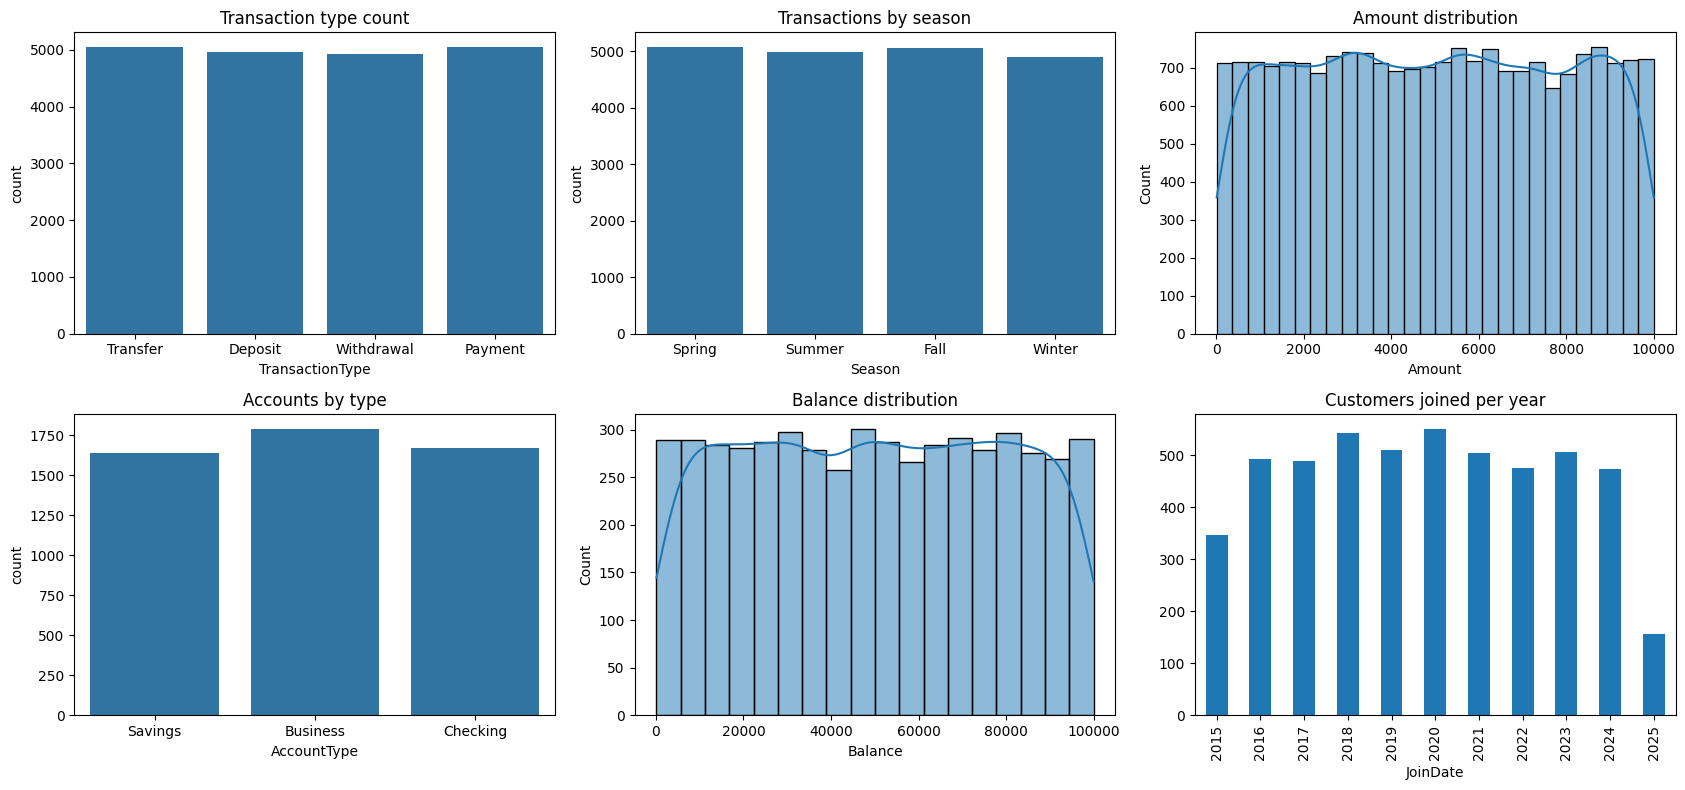

In [15]:
fig, ax = plt.subplots(2, 3, figsize=(17, 8))

sns.countplot(data=transactions, x='TransactionType', ax=ax[0, 0])
ax[0, 0].set_title('Transaction type count')

sns.countplot(data=transactions, x='Season', order=['Spring', 'Summer', 'Fall', 'Winter'], ax=ax[0, 1])
ax[0, 1].set_title('Transactions by season')

sns.histplot(data=transactions, x='Amount', kde=True, ax=ax[0, 2])
ax[0, 2].set_title('Amount distribution')

sns.countplot(data=accounts, x='AccountType', ax=ax[1, 0])
ax[1, 0].set_title('Accounts by type')

sns.histplot(data=accounts, x='Balance', kde=True, ax=ax[1, 1])
ax[1, 1].set_title('Balance distribution')

customers['JoinDate'].dt.year.value_counts().sort_index().plot(kind='bar', ax=ax[1, 2])
ax[1, 2].set_title('Customers joined per year')

plt.tight_layout()
plt.show()

### Loans, cards, support and products

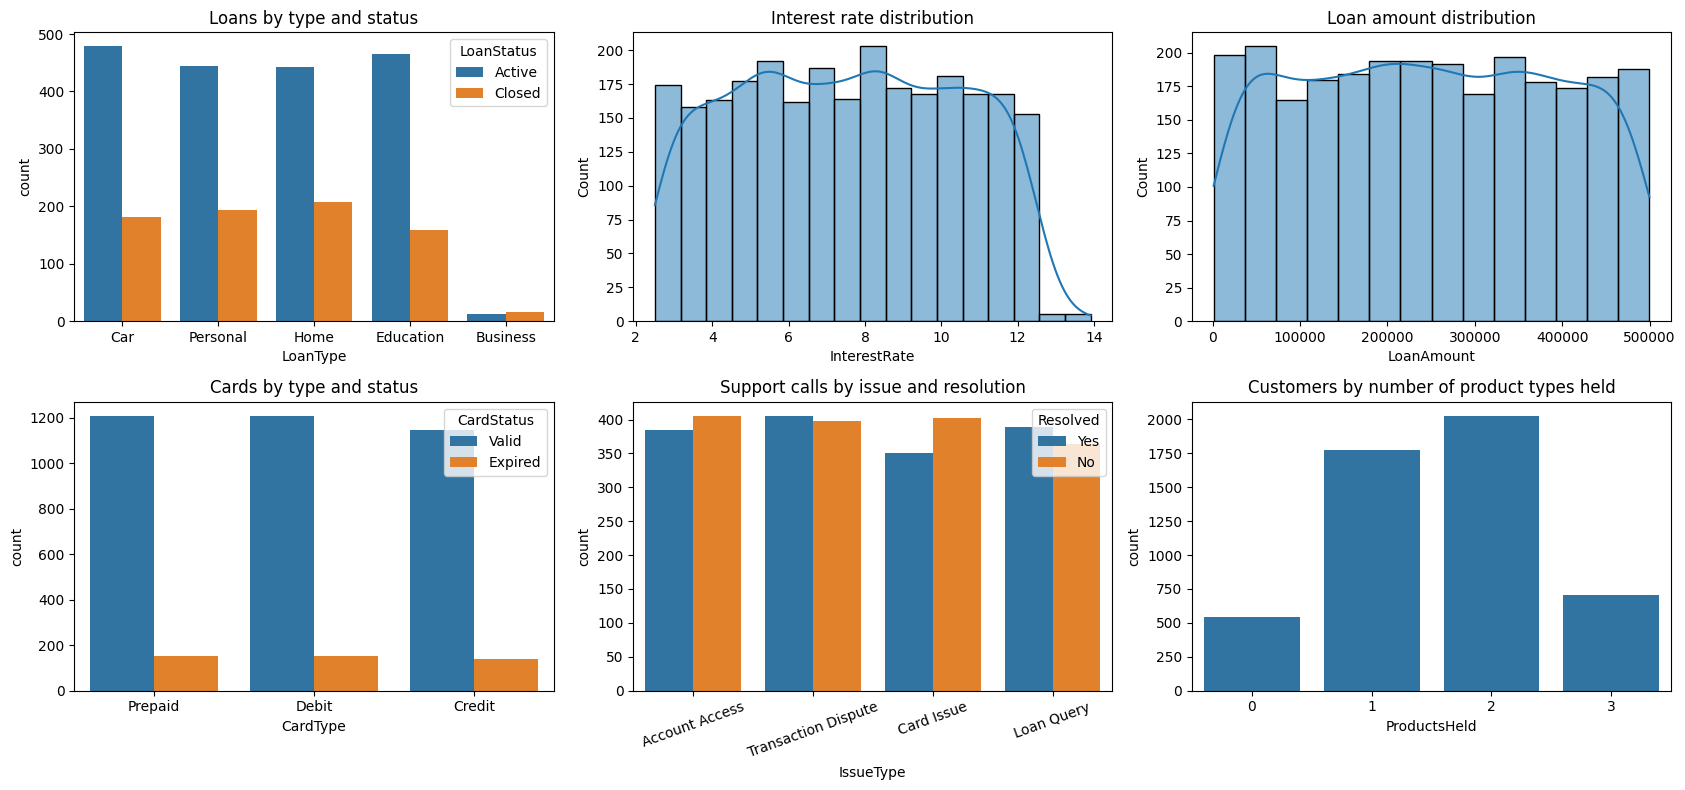

In [17]:
fig, ax = plt.subplots(2, 3, figsize=(17, 8))

sns.countplot(data=loans, x='LoanType', hue='LoanStatus', ax=ax[0, 0])
ax[0, 0].set_title('Loans by type and status')

sns.histplot(data=loans, x='InterestRate', kde=True, ax=ax[0, 1])
ax[0, 1].set_title('Interest rate distribution')

sns.histplot(data=loans, x='LoanAmount', kde=True, ax=ax[0, 2])
ax[0, 2].set_title('Loan amount distribution')

sns.countplot(data=cards, x='CardType', hue='CardStatus', ax=ax[1, 0])
ax[1, 0].set_title('Cards by type and status')

sns.countplot(data=SupportCalls, x='IssueType', hue='Resolved', ax=ax[1, 1])
ax[1, 1].set_title('Support calls by issue and resolution')
ax[1, 1].tick_params(axis='x', rotation=20)

sns.countplot(data=customers, x='ProductsHeld', ax=ax[1, 2])
ax[1, 2].set_title('Customers by number of product types held')

plt.tight_layout()
plt.show()

## 7. Validation

In [19]:
assert customers['CustomerID'].is_unique
assert accounts['AccountID'].is_unique
assert loans['LoanID'].is_unique
assert cards['CardID'].is_unique
assert SupportCalls['CallID'].is_unique
assert transactions['TransactionID'].is_unique

for df in (accounts, loans, cards, SupportCalls):
    assert df['CustomerID'].isin(customers['CustomerID']).all()
assert transactions['AccountID'].isin(accounts['AccountID']).all()

assert 'CardNumber' not in cards.columns
assert transactions['CashFlow'].notna().all()
for df in (customers, accounts, loans, cards, SupportCalls, transactions):
    assert not df.isnull().any().any()
print('All checks passed')

All checks passed


## 8. Export clean files for Power BI

Dates are saved as `YYYY-MM-DD` so Power BI reads them the same way on any computer.

In [23]:
import os

# Define the path to your new 'clean' subfolder
output_dir = r'C:\Users\LENOVO\Desktop\Programmation\Banking Customer & Operations\Data\clean'

# Automatically create the folder if it doesn't exist yet
os.makedirs(output_dir, exist_ok=True)

clean_tables = {
    'customers': customers, 
    'accounts': accounts, 
    'loans': loans,
    'cards': cards, 
    'support_calls': SupportCalls, 
    'transactions': transactions
}

for name, df in clean_tables.items():
    # Construct the full file path safely
    file_path = os.path.join(output_dir, f'{name}.csv')
    
    # Save to CSV
    df.to_csv(file_path, index=False, date_format='%Y-%m-%d')
    print(f'{name:<20} {df.shape[0]:>6} rows, columns: {list(df.columns)}')

customers              5050 rows, columns: ['CustomerID', 'FirstName', 'LastName', 'JoinDate', 'State', 'IsMilitary', 'Accounts', 'Loans', 'Cards', 'ProductsHeld']
accounts               5100 rows, columns: ['AccountID', 'CustomerID', 'AccountType', 'Balance', 'CreatedDate', 'BeforeCustomerJoin']
loans                  2600 rows, columns: ['LoanID', 'CustomerID', 'LoanType', 'LoanAmount', 'InterestRate', 'LoanStartDate', 'LoanEndDate', 'BeforeCustomerJoin', 'LoanTermYears', 'LoanStatus']
cards                  4000 rows, columns: ['CardID', 'CustomerID', 'CardType', 'IssuedDate', 'ExpirationDate', 'BeforeCustomerJoin', 'CardStatus']
support_calls          3100 rows, columns: ['CallID', 'CustomerID', 'CallDate', 'IssueType', 'Resolved', 'BeforeCustomerJoin', 'IsResolved']
transactions          20000 rows, columns: ['TransactionID', 'AccountID', 'TransactionType', 'Amount', 'TransactionDate', 'Season', 'BeforeAccountCreation', 'Year', 'YearMonth', 'CashFlow']


## 9. Cleaning decisions (summary)

| Issue | Found | Decision |
|---|---|---|
| Junk index columns | `Unnamed: 0`, `Unnamed: 1` | Dropped |
| Dates stored as text | Several columns in 5 tables | Converted, CSV files with an explicit format, exported as ISO |
| `State = 'Army'` | 531 customers, all with military addresses | Renamed + `IsMilitary` flag |
| Phone / Email / Address | Inconsistent, personal data, not needed | Dropped |
| `CardNumber` | Sensitive, not needed | Dropped |
| Customers with no account | 1,851 (37%) | Kept, use left joins |
| Customers with no product at all | 541 (11%) | Kept, new column `ProductsHeld` |
| Rows dated before the customer joined | Loans 30%, cards 25%, accounts 49%, calls 4% | Flagged, not deleted |
| Transactions before account creation | 3,172 (16%) | Flagged, not deleted |
| Tables on different timelines | Transactions and calls end 2025-05, loans reach 2026-06 | Fixed `REF_DATE` for status columns, compare 2023 vs 2024 |
| Loan and card status | 757 loans closed, 442 cards expired at `REF_DATE` | New columns `LoanStatus`, `CardStatus` |
| Transfer direction | Not in the data | `CashFlow = 'Unknown'` |
| Missing values / duplicates / outliers | None | Nothing to do |

## Next step: Power BI

Relationships: `customers (1)` -> `accounts`, `loans`, `cards`, `support calls` (many), and `accounts (1)` -> `transactions` (many), plus a Date table.